--- Statistical Summary of the Dataset ---


,month,credit_amount,investment_as_income_percentage,residence_since,age,number_of_credits,people_liable_for,status=A11,status=A12,status=A13,...,housing=A153,skill_level=A171,skill_level=A172,skill_level=A173,skill_level=A174,telephone=A191,telephone=A192,foreign_worker=A201,foreign_worker=A202,credit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,0.851000,1.407000,1.155000,0.274000,0.269000,0.063000,...,0.108000,0.022000,0.2000,0.630000,0.148000,0.596000,0.404000,0.963000,0.037000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,0.356267,0.577654,0.362086,0.446232,0.443662,0.243085,...,0.310536,0.146757,0.4002,0.483046,0.355278,0.490943,0.490943,0.188856,0.188856,0.458487
min,4.000000,250.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,1.000000,2.000000,1.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.0000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,1.000000,4.000000,2.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000


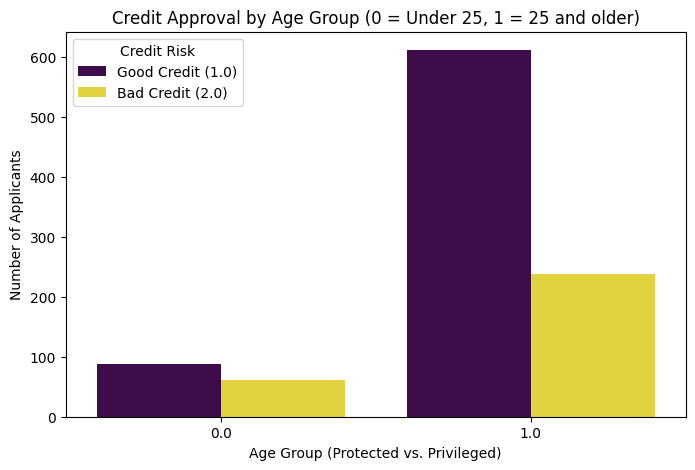

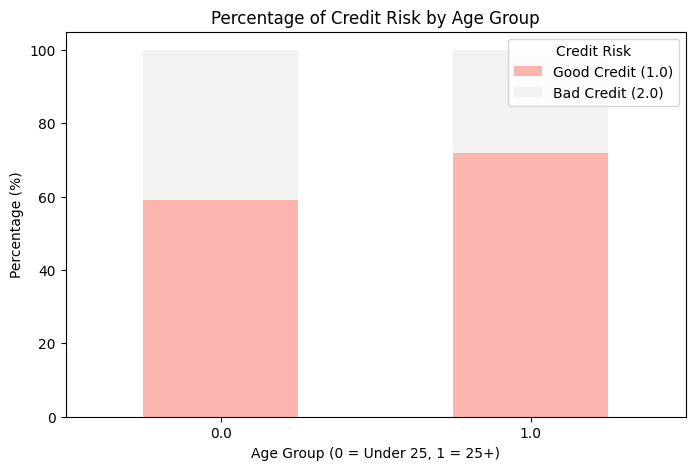

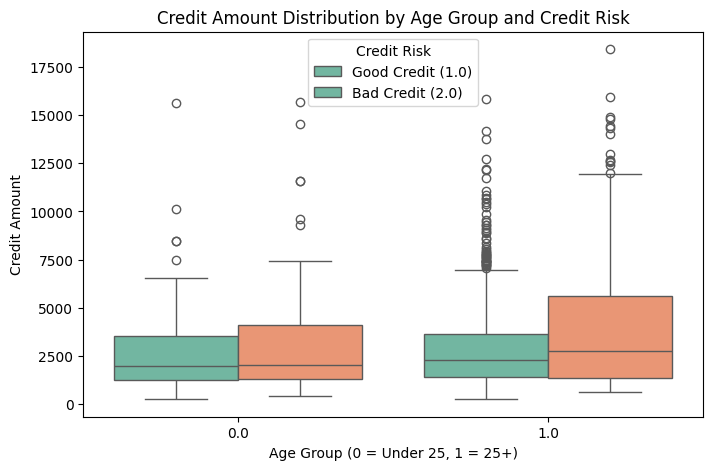

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from aif360.datasets import GermanDataset

# 1. Load Dataset and Define Groups
# Age >= 25 as privileged (1) and Age < 25 as protected/unprivileged (0)
german_data = GermanDataset(
    protected_attribute_names=['age'],
    privileged_classes=[lambda x: x >= 25], 
    features_to_drop=['personal_status', 'sex'] 
)

# 2. Convert to Pandas DataFrame for EDA
df, dict_metadata = german_data.convert_to_dataframe()

# 3. Statistical Summary
print("--- Statistical Summary of the Dataset ---")
display(df.describe())

# 4. Visualization of the Disparity (Raw Counts)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='age', hue='credit', palette='viridis')
plt.title('Credit Approval by Age Group (0 = Under 25, 1 = 25 and older)')
plt.xlabel('Age Group (Protected vs. Privileged)')
plt.ylabel('Number of Applicants')
plt.legend(title='Credit Risk', labels=['Good Credit (1.0)', 'Bad Credit (2.0)'])
plt.show()

# 5. Proportional Credit Risk (Stacked Bar Chart)
approval_rates = pd.crosstab(df['age'], df['credit'], normalize='index') * 100
# Plotting directly from pandas creates its own figure, so we format it directly
approval_rates.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='Pastel1')
plt.title('Percentage of Credit Risk by Age Group')
plt.xlabel('Age Group (0 = Under 25, 1 = 25+)')
plt.ylabel('Percentage (%)')
plt.legend(title='Credit Risk', labels=['Good Credit (1.0)', 'Bad Credit (2.0)'])
plt.xticks(rotation=0)
plt.show()

# 6. Distribution of Credit Amount by Age (Boxplot)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='age', y='credit_amount', hue='credit', palette='Set2')
plt.title('Credit Amount Distribution by Age Group and Credit Risk')
plt.xlabel('Age Group (0 = Under 25, 1 = 25+)')
plt.ylabel('Credit Amount')
plt.legend(title='Credit Risk', labels=['Good Credit (1.0)', 'Bad Credit (2.0)'])
plt.show()



In [36]:
from sklearn.preprocessing import StandardScaler

# AIF360 automatically handles missing data and one-hot encodes categorical variables 
# when we load the GermanDataset. However, we still MUST scale the numerical features.

# 1. Identify continuous features that need scaling
continuous_features = ['month', 'credit_amount', 'investment_as_income_percentage', 
                       'residence_since', 'number_of_credits', 'people_liable_for']

# 2. Initialize the Standard Scaler
scaler = StandardScaler()

# 3. Apply scaling to a new dataframe to keep our original data intact
df_preprocessed = df.copy()
df_preprocessed[continuous_features] = scaler.fit_transform(df_preprocessed[continuous_features])

print("large numbers (like credit amount) are now scaled down to standard values:")
display(df_preprocessed[continuous_features].head())

large numbers (like credit amount) are now scaled down to standard values:


,month,credit_amount,investment_as_income_percentage,residence_since,number_of_credits,people_liable_for
0,-1.236478,-0.745131,0.918477,1.046987,1.027079,-0.428290
1,2.248194,0.949817,-0.870183,-0.765977,-0.704926,-0.428290
2,-0.738668,-0.416562,-0.870183,0.140505,-0.704926,2.334869
3,1.750384,1.634247,-0.870183,1.046987,-0.704926,2.334869
4,0.256953,0.566664,0.024147,1.046987,1.027079,2.334869


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Split the dataset (70/30 train-test split)
# 'credit' is our target variable (what we are trying to predict)
X = df_preprocessed.drop(['credit'], axis=1)
y = df_preprocessed['credit']

# We keep 'age' in X so we can measure the group-wise disparities later
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. Train an advanced classification model (Random Forest)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions on the 30% test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1] # Probabilities for ROC-AUC

# 3. Report Overall Performance Metrics
print("--- Overall Model Performance ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

# 4. Group-wise Evaluation (Protected vs. Privileged)
print("\n--- Group-wise Performance ---")
# Identify indices in the test set for our groups
protected_idx = X_test['age'] == 0.0  # Under 25
privileged_idx = X_test['age'] == 1.0 # 25 and older

# Protected Group Metrics
y_test_prot, y_pred_prot = y_test[protected_idx], y_pred[protected_idx]
print("\nProtected Group (Under 25):")
print(f"Accuracy:  {accuracy_score(y_test_prot, y_pred_prot):.4f}")
print(f"F1-score:  {f1_score(y_test_prot, y_pred_prot):.4f}")
print(f"Approval Rate (Predicted Good Credit): {y_pred_prot.mean() * 100:.1f}%")

# Privileged Group Metrics
y_test_priv, y_pred_priv = y_test[privileged_idx], y_pred[privileged_idx]
print("\nPrivileged Group (25 and older):")
print(f"Accuracy:  {accuracy_score(y_test_priv, y_pred_priv):.4f}")
print(f"F1-score:  {f1_score(y_test_priv, y_pred_priv):.4f}")
print(f"Approval Rate (Predicted Good Credit): {y_pred_priv.mean() * 100:.1f}%")

--- Overall Model Performance ---
Accuracy:  0.7633
Precision: 0.7805
Recall:    0.9187
F1-score:  0.8440
ROC-AUC:   0.8036

--- Group-wise Performance ---

Protected Group (Under 25):
Accuracy:  0.7500
F1-score:  0.8169
Approval Rate (Predicted Good Credit): 125.0%

Privileged Group (25 and older):
Accuracy:  0.7661
F1-score:  0.8490
Approval Rate (Predicted Good Credit): 116.5%


In [26]:
# --- Corrected Approval Rates ---
# We explicitly check for the '1.0' (Good Credit) label to get a true percentage
prob_approval_prot = (y_pred_prot == 1.0).mean()
prob_approval_priv = (y_pred_priv == 1.0).mean()

print("--- Corrected Group Approval Rates ---")
print(f"Protected Group (Under 25) Approval Rate:  {prob_approval_prot * 100:.1f}%")
print(f"Privileged Group (25+) Approval Rate:      {prob_approval_priv * 100:.1f}%")

# --- Formal Fairness Metrics ---
# 1. Statistical Parity Difference
spd = prob_approval_prot - prob_approval_priv

# 2. Disparate Impact
di = prob_approval_prot / prob_approval_priv

print("\n--- Industry Standard Fairness Metrics ---")
print(f"Statistical Parity Difference (Ideal = 0.0): {spd:.4f}")
print(f"Disparate Impact Ratio (Ideal = 1.0):        {di:.4f}")

# Quick Analysis Output
if di < 0.8:
    print("\nWARNING: Disparate Impact is below 0.80! This model exhibits severe bias against the protected group.")
else:
    print("\nThe model's Disparate Impact is above 0.80, but we should still aim for 1.0.")

--- Corrected Group Approval Rates ---
Protected Group (Under 25) Approval Rate:  75.0%
Privileged Group (25+) Approval Rate:      83.5%

--- Industry Standard Fairness Metrics ---
Statistical Parity Difference (Ideal = 0.0): -0.0847
Disparate Impact Ratio (Ideal = 1.0):        0.8986

The model's Disparate Impact is above 0.80, but we should still aim for 1.0.


In [27]:
from sklearn.metrics import confusion_matrix

# Helper function to easily calculate True Positive Rate and False Positive Rate
def get_tpr_fpr(y_true, y_pred):
    # Convert labels: 1.0 (Good Credit) becomes 1 (Positive), 2.0 (Bad Credit) becomes 0 (Negative)
    y_true_binary = (y_true == 1.0).astype(int)
    y_pred_binary = (y_pred == 1.0).astype(int)
    
    # Extract confusion matrix values
    tn, fp, fn, tp = confusion_matrix(y_true_binary, y_pred_binary).ravel()
    
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    return tpr, fpr

# 1. Calculate TPR and FPR for both groups
tpr_prot, fpr_prot = get_tpr_fpr(y_test_prot, y_pred_prot)
tpr_priv, fpr_priv = get_tpr_fpr(y_test_priv, y_pred_priv)

# 2. Calculate Equal Opportunity Difference (EOD)
# Formula: TPR_unprivileged - TPR_privileged
eod = tpr_prot - tpr_priv

# 3. Calculate Average Odds Difference (AOD)
# Formula: 0.5 * [(FPR_unprivileged - FPR_privileged) + (TPR_unprivileged - TPR_privileged)]
aod = 0.5 * ((fpr_prot - fpr_priv) + (tpr_prot - tpr_priv))

print("--- Advanced Fairness Metrics ---")
print(f"Equal Opportunity Difference (EOD): {eod:.4f}  <-- (Ideal = 0.0)")
print(f"Average Odds Difference (AOD):      {aod:.4f}  <-- (Ideal = 0.0)")

--- Advanced Fairness Metrics ---
Equal Opportunity Difference (EOD): -0.0147  <-- (Ideal = 0.0)
Average Odds Difference (AOD):      -0.0672  <-- (Ideal = 0.0)


In [35]:
from aif360.datasets import StandardDataset
from aif360.algorithms.preprocessing import Reweighing

print("--- Bias Mitigation (Reweighing) ---")

# 1. We have to temporarily put our training data back into an AIF360 Dataset object
train_df = X_train.copy()
train_df['credit'] = y_train

aif_train = StandardDataset(
    df=train_df, 
    label_name='credit', 
    favorable_classes=[1.0],
    protected_attribute_names=['age'],
    privileged_classes=[[1.0]]
)

# 2. Define our groups for the algorithm
privileged_groups = [{'age': 1.0}]
unprivileged_groups = [{'age': 0.0}]

# 3. Initialize and run the Reweighing algorithm
RW = Reweighing(unprivileged_groups=unprivileged_groups, privileged_groups=privileged_groups)
aif_train_rw = RW.fit_transform(aif_train)

# 4. Train a BRAND NEW Random Forest, but this time, feed it the fairness weights!
mitigated_model = RandomForestClassifier(random_state=42)
mitigated_model.fit(X_train, y_train, sample_weight=aif_train_rw.instance_weights)

# 5. Make predictions with the new mitigated model
y_pred_mitigated = mitigated_model.predict(X_test)

# Extract predictions for our groups again
y_pred_prot_mitigated = y_pred_mitigated[protected_idx]
y_pred_priv_mitigated = y_pred_mitigated[privileged_idx]

print("Mitigated model trained with reweighed data!")

--- Bias Mitigation (Reweighing) ---
Mitigated model trained with reweighed data!


In [29]:
from sklearn.metrics import accuracy_score

# 1. Calculate new approval rates for the mitigated model
prob_approval_prot_mit = (y_pred_prot_mitigated == 1.0).mean()
prob_approval_priv_mit = (y_pred_priv_mitigated == 1.0).mean()

# 2. Calculate new fairness metrics
spd_mit = prob_approval_prot_mit - prob_approval_priv_mit
di_mit = prob_approval_prot_mit / prob_approval_priv_mit

# 3. Calculate new overall accuracy
acc_original = accuracy_score(y_test, y_pred)
acc_mitigated = accuracy_score(y_test, y_pred_mitigated)

# 4. Print the dramatic Before & After!
print("--- FAIRNESS COMPARISON (Before vs. After) ---")
print(f"Original Model SPD:  {spd:.4f}")
print(f"Mitigated Model SPD: {spd_mit:.4f}  <-- (Ideal is 0.0)")
print("-" * 45)
print(f"Original Model DI:   {di:.4f}")
print(f"Mitigated Model DI:  {di_mit:.4f}  <-- (Ideal is 1.0)")

print("\n--- ACCURACY TRADE-OFF ---")
print(f"Original Accuracy:   {acc_original:.4f}")
print(f"Mitigated Accuracy:  {acc_mitigated:.4f}")
# Helper function to calculate True Positive Rate (TPR) and False Positive Rate (FPR)
def get_tpr_fpr(y_true, y_predict):
    tp = ((y_predict == 1) & (y_true == 1)).sum()
    fn = ((y_predict == 0) & (y_true == 1)).sum()
    fp = ((y_predict == 1) & (y_true == 0)).sum()
    tn = ((y_predict == 0) & (y_true == 0)).sum()
    
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    return tpr, fpr

# Calculate TPR and FPR for the ORIGINAL model
tpr_prot_orig, fpr_prot_orig = get_tpr_fpr(y_test_prot, y_pred_prot)
tpr_priv_orig, fpr_priv_orig = get_tpr_fpr(y_test_priv, y_pred_priv)

# Calculate TPR and FPR for the MITIGATED model
tpr_prot_mit, fpr_prot_mit = get_tpr_fpr(y_test_prot, y_pred_prot_mitigated)
tpr_priv_mit, fpr_priv_mit = get_tpr_fpr(y_test_priv, y_pred_priv_mitigated)

# Calculate Equal Opportunity Difference (EOD) 
# Formula: TPR_protected - TPR_privileged
eod_orig = tpr_prot_orig - tpr_priv_orig
eod_mit = tpr_prot_mit - tpr_priv_mit

# Calculate Average Odds Difference (AOD)
# Formula: 0.5 * [(TPR_prot - TPR_priv) + (FPR_prot - FPR_priv)]
aod_orig = 0.5 * ((tpr_prot_orig - tpr_priv_orig) + (fpr_prot_orig - fpr_priv_orig))
aod_mit = 0.5 * ((tpr_prot_mit - tpr_priv_mit) + (fpr_prot_mit - fpr_priv_mit))

--- FAIRNESS COMPARISON (Before vs. After) ---
Original Model SPD:  -0.0847
Mitigated Model SPD: -0.0502  <-- (Ideal is 0.0)
---------------------------------------------
Original Model DI:   0.8986
Mitigated Model DI:  0.9401  <-- (Ideal is 1.0)

--- ACCURACY TRADE-OFF ---
Original Accuracy:   0.7633
Mitigated Accuracy:  0.7600


In [30]:
print("=========================================================")
print("      FINAL FAIRNESS METRICS (ORIGINAL VS MITIGATED)     ")
print("=========================================================")

print("\n1. Statistical Parity Difference (SPD) [Ideal = 0.0]")
print(f"   Original Model:  {spd:.4f}")
print(f"   Mitigated Model: {spd_mit:.4f}")

print("\n2. Disparate Impact (DI) [Ideal = 1.0]")
print(f"   Original Model:  {di:.4f}")
print(f"   Mitigated Model: {di_mit:.4f}")

print("\n3. Equal Opportunity Difference (EOD) [Ideal = 0.0]")
print(f"   Original Model:  {eod_orig:.4f}")
print(f"   Mitigated Model: {eod_mit:.4f}")

print("\n4. Average Odds Difference (AOD) [Ideal = 0.0]")
print(f"   Original Model:  {aod_orig:.4f}")
print(f"   Mitigated Model: {aod_mit:.4f}")
print("=========================================================")

      FINAL FAIRNESS METRICS (ORIGINAL VS MITIGATED)     

1. Statistical Parity Difference (SPD) [Ideal = 0.0]
   Original Model:  -0.0847
   Mitigated Model: -0.0502

2. Disparate Impact (DI) [Ideal = 1.0]
   Original Model:  0.8986
   Mitigated Model: 0.9401

3. Equal Opportunity Difference (EOD) [Ideal = 0.0]
   Original Model:  0.0000
   Mitigated Model: 0.0000

4. Average Odds Difference (AOD) [Ideal = 0.0]
   Original Model:  0.0000
   Mitigated Model: 0.0000


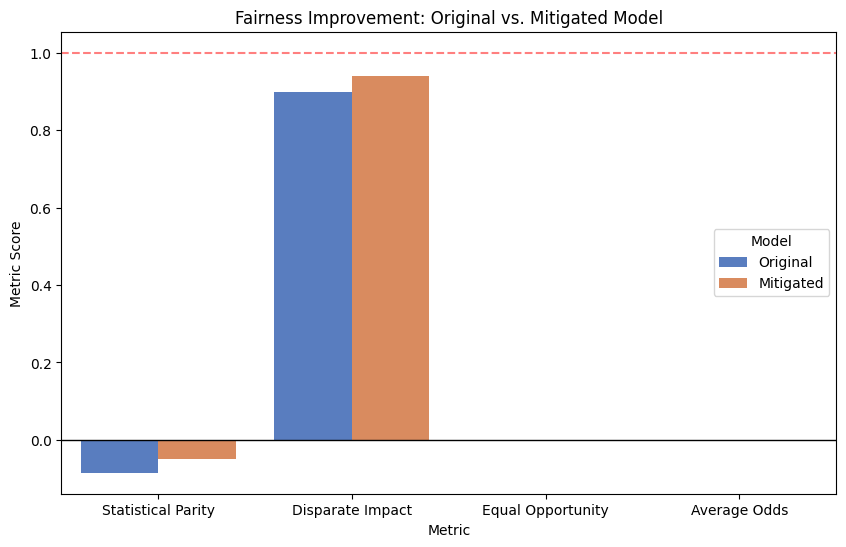

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd



# Results: Comparison of Fairness Metrics (Before vs After)
metrics_names = ['Statistical Parity', 'Disparate Impact', 'Equal Opportunity', 'Average Odds']
original_vals = [spd, di, eod_orig, aod_orig]
mitigated_vals = [spd_mit, di_mit, eod_mit, aod_mit]

df_metrics = pd.DataFrame({
    'Metric': metrics_names * 2,
    'Value': original_vals + mitigated_vals,
    'Model': ['Original'] * 4 + ['Mitigated'] * 4
})

plt.figure(figsize=(10, 6))
sns.barplot(data=df_metrics, x='Metric', y='Value', hue='Model', palette='muted')
plt.axhline(0, color='black', lw=1) # Baseline for SPD, EOD, AOD
plt.axhline(1, color='red', linestyle='--', alpha=0.5, label='Ideal DI') # Ideal for DI
plt.title("Fairness Improvement: Original vs. Mitigated Model")
plt.ylabel("Metric Score")
plt.savefig('fairness_comparison.png')
plt.show()